In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Generate sample dataset

X, y = make_blobs(
    n_samples=200,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

data = pd.DataFrame(X, columns=['Feature1', 'Feature2'])

print("Dataset created successfully!")
data.head()


Dataset created successfully!


,Feature1,Feature2
0,6.505653,2.447003
1,-5.128943,9.836189
2,-6.891874,-7.777364
3,-8.327712,-8.287573
4,-7.468992,-6.030507


In [3]:
# Display dataset information

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
print(data.info())

print("\nStatistical Summary:")
print(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())


Dataset Shape: (200, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Feature1  200 non-null    float64
 1   Feature2  200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB
None

Statistical Summary:
         Feature1    Feature2
count  200.000000  200.000000
mean    -1.564904    1.443716
std      4.811213    6.549258
min     -9.003523   -8.832197
25%     -6.083157   -6.260380
50%     -2.563116    2.237789
75%      3.877668    8.388872
max      6.954537   11.477528

Missing Values:
Feature1    0
Feature2    0
dtype: int64


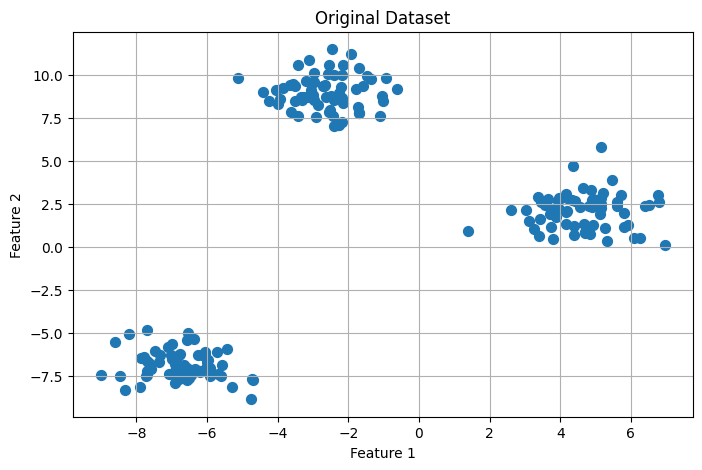

In [4]:
# Visualize original data points

plt.figure(figsize=(8, 5))

plt.scatter(
    data['Feature1'],
    data['Feature2'],
    s=50
)

plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

plt.show()

In [5]:
# Standardize the features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(data)

print("Data standardized successfully!")

Data standardized successfully!


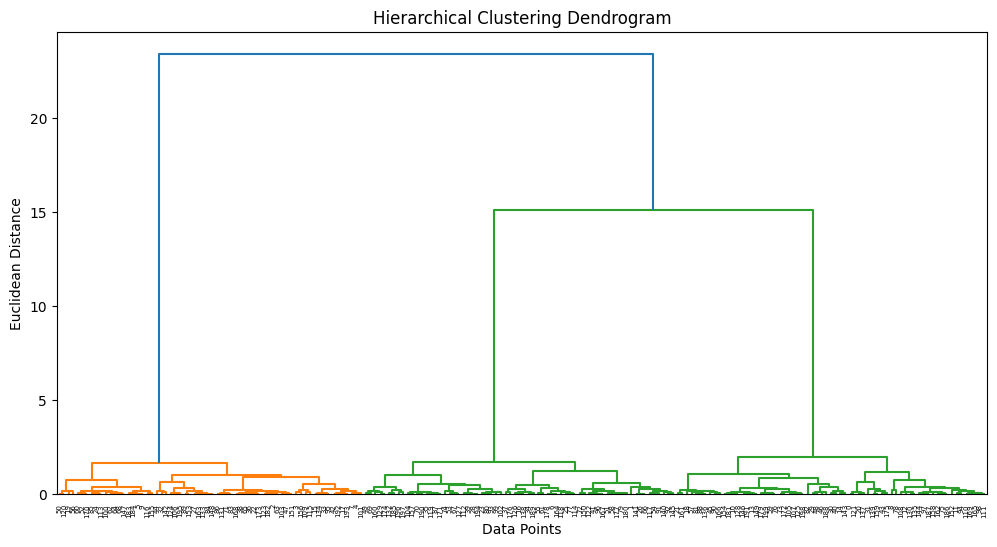

In [6]:
# Generate linkage matrix

linked = linkage(X_scaled, method='ward')

# Plot dendrogram

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

In [7]:
# Apply Agglomerative Clustering

hc = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

cluster_labels = hc.fit_predict(X_scaled)

# Add cluster labels to dataset

data['Cluster'] = cluster_labels

print("Clustering completed successfully!")

data.head()

Clustering completed successfully!


,Feature1,Feature2,Cluster
0,6.505653,2.447003,0
1,-5.128943,9.836189,2
2,-6.891874,-7.777364,1
3,-8.327712,-8.287573,1
4,-7.468992,-6.030507,1


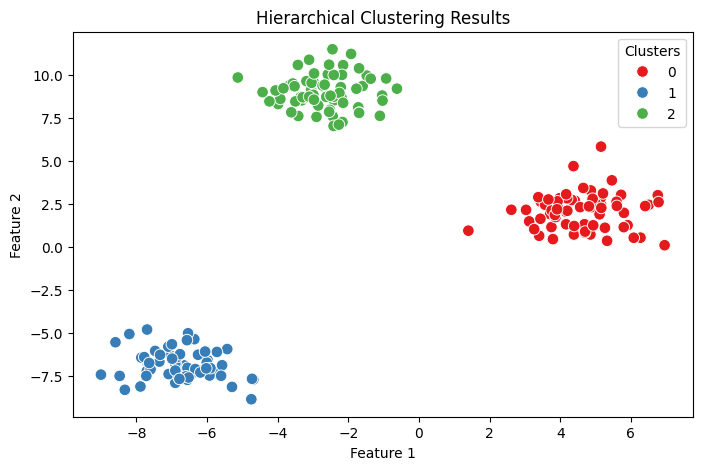

In [8]:
# Visualize hierarchical clusters

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x='Feature1',
    y='Feature2',
    hue='Cluster',
    palette='Set1',
    s=70
)

plt.title("Hierarchical Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(title="Clusters")

plt.show()

In [9]:
# Calculate Silhouette Score

score = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.8472


In [10]:
# Count the number of data points in each cluster

print("Number of Clusters:", data['Cluster'].nunique())

print("\nCluster Distribution:")
print(data['Cluster'].value_counts().sort_index())

print("\nCluster Mean Values:")
print(data.groupby('Cluster')[['Feature1', 'Feature2']].mean())

Number of Clusters: 3

Cluster Distribution:
Cluster
0    67
1    66
2    67
Name: count, dtype: int64

Cluster Mean Values:
         Feature1  Feature2
Cluster                    
0        4.632182  2.101214
1       -6.745394 -6.851443
2       -2.658821  8.957568


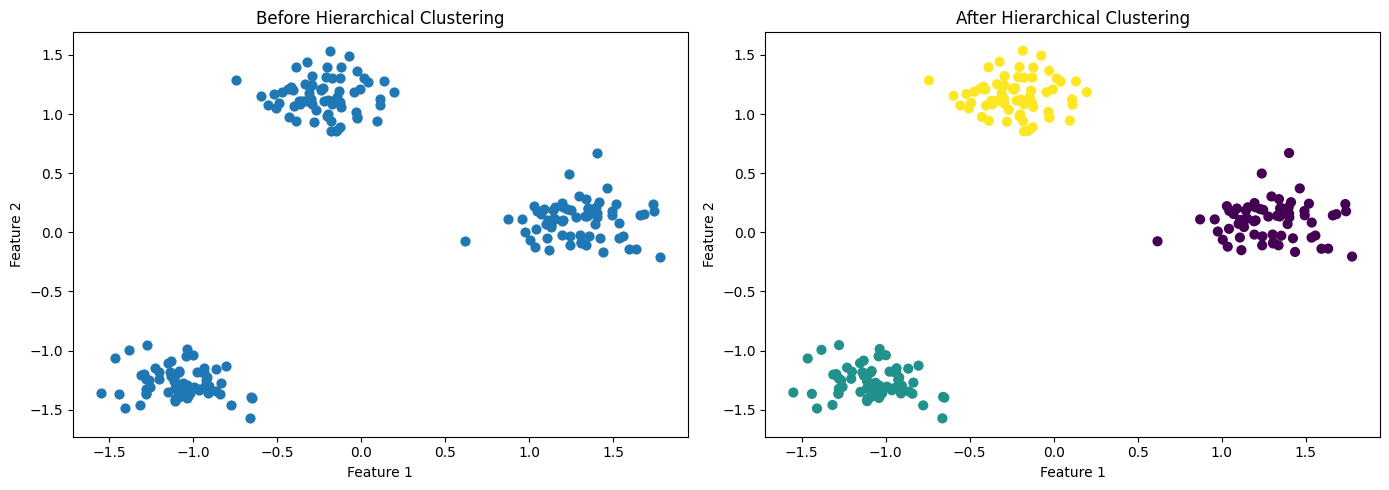

In [11]:
# Final clustering visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original dataset

axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    s=40
)

axes[0].set_title("Before Hierarchical Clustering")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Clustered dataset

axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=40
)

axes[1].set_title("After Hierarchical Clustering")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [12]:
# Save final results as CSV

data.to_csv(
    'Hierarchical_Clustering_Results.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [13]:
from google.colab import files

files.download('Hierarchical_Clustering_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>